# Step 1 — Exploring the UAH-DriveSet

**Paper:** E. Romera, L. M. Bergasa, R. Arroyo, *"Need Data for Driver Behaviour Analysis?
Presenting the Public UAH-DriveSet"*, IEEE ITSC 2016.

In this notebook we:
1. Load all 40 trips and check what the dataset contains.
2. Look at the files of a single trip.
3. Compare **Normal**, **Aggressive** and **Drowsy** driving for the same driver on the same road.
4. Look at the app's own trip scores (`SEMANTIC_FINAL.txt`), which we will try to reproduce in later steps.

All the loading code is in `uah_driveset.py`.

In [1]:
import sys
sys.path.insert(0, "..")  # so we can import uah_driveset.py from the project root

import matplotlib.pyplot as plt
import pandas as pd
from uah_driveset import list_trips, load_trip, load_summaries, DATA_ROOT

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (12, 4)
COLORS = {"NORMAL": "tab:green", "AGGRESSIVE": "tab:red", "DROWSY": "tab:blue"}
print("Data folder:", DATA_ROOT.resolve())

Data folder: D:\Mini_Project\UAH-DRIVESET-v1\UAH-DRIVESET-v1


## 1. All trips

Each trip folder name tells us the driver, the behaviour they acted out, and the road type.

In [2]:
trips = list_trips()
print(len(trips), "trips")
trips.drop(columns="path").head(10)

40 trips


,trip_id,driver,behavior,road,distance_km,start
0,20151110175712-16km-D1-NORMAL1-SECONDARY,D1,NORMAL,SECONDARY,16,2015-11-10 17:57:12
1,20151110180824-16km-D1-NORMAL2-SECONDARY,D1,NORMAL,SECONDARY,16,2015-11-10 18:08:24
2,20151111123124-25km-D1-NORMAL-MOTORWAY,D1,NORMAL,MOTORWAY,25,2015-11-11 12:31:24
3,20151111125233-24km-D1-AGGRESSIVE-MOTORWAY,D1,AGGRESSIVE,MOTORWAY,24,2015-11-11 12:52:33
4,20151111132348-25km-D1-DROWSY-MOTORWAY,D1,DROWSY,MOTORWAY,25,2015-11-11 13:23:48
5,20151111134545-16km-D1-AGGRESSIVE-SECONDARY,D1,AGGRESSIVE,SECONDARY,16,2015-11-11 13:45:45
6,20151111135612-13km-D1-DROWSY-SECONDARY,D1,DROWSY,SECONDARY,13,2015-11-11 13:56:12
7,20151120131714-26km-D2-NORMAL-MOTORWAY,D2,NORMAL,MOTORWAY,26,2015-11-20 13:17:14
8,20151120133502-26km-D2-AGGRESSIVE-MOTORWAY,D2,AGGRESSIVE,MOTORWAY,26,2015-11-20 13:35:02
9,20151120135152-25km-D2-DROWSY-MOTORWAY,D2,DROWSY,MOTORWAY,25,2015-11-20 13:51:52


In [3]:
pd.crosstab(trips["behavior"], trips["road"], margins=True)

road,MOTORWAY,SECONDARY,All
behavior,,,
AGGRESSIVE,6,5,11
DROWSY,6,6,12
NORMAL,6,11,17
All,18,22,40


In [4]:
pd.crosstab(trips["driver"], trips["behavior"])

behavior,AGGRESSIVE,DROWSY,NORMAL
driver,,,
D1,2,2,3
D2,2,2,3
D3,2,2,3
D4,2,2,3
D5,2,2,3
D6,1,2,2


## 2. What is inside one trip?

`load_trip()` returns one table per file:

| Key | File | What it contains |
|---|---|---|
| `gps` | RAW_GPS | speed (km/h), position, altitude, course — about 1 row per second |
| `accel` | RAW_ACCELEROMETERS | accelerations in g (raw and Kalman-filtered), roll/pitch/yaw — about 10 rows per second |
| `lanes` | PROC_LANE_DETECTION | car position inside the lane, from the camera |
| `vehicles` | PROC_VEHICLE_DETECTION | distance and time-to-impact to the car ahead, from the camera |
| `osm` | PROC_OPENSTREETMAP_DATA | speed limit and road type from OpenStreetMap |
| `lane_changes` | EVENTS_LIST_LANE_CHANGES | each lane change and how long it took |
| `events` | EVENTS_INERTIAL | each braking / turning / acceleration event, with level low/medium/high |
| `summary` | SEMANTIC_FINAL | the app's final scores for the whole trip |

In [5]:
trip_row = trips[(trips.driver == "D1") & (trips.behavior == "AGGRESSIVE") & (trips.road == "SECONDARY")].iloc[0]
trip = load_trip(trip_row)
print(trip_row.trip_id)
for name, df in trip.items():
    print(f"{name:13s} {df.shape}")

20151111134545-16km-D1-AGGRESSIVE-SECONDARY
gps           (515, 12)
accel         (5315, 11)
lanes         (12660, 5)
vehicles      (3462, 5)
osm           (183, 10)
lane_changes  (1, 6)
events        (12, 8)
summary       (54,)


In [6]:
trip["gps"].head()

,time,speed_kmh,lat,lon,altitude,vert_accuracy,horiz_accuracy,course,course_change,unused1,unused2,unused3
0,22.19,100.4,40.519108,-3.410149,615.3,6,5,324.5,0.352,0,0,0
1,23.21,100.4,40.519314,-3.410343,615.9,4,5,324.5,0.352,0,0,0
2,24.19,100.9,40.519516,-3.410536,616.6,4,5,324.1,0.352,0,0,0
3,25.19,101.2,40.519726,-3.410728,616.4,4,5,324.5,0.352,0,0,0
4,26.19,102.3,40.519939,-3.410926,617.2,4,5,324.5,0.352,0,0,0


In [7]:
trip["accel"].head()

,time,active,acc_x,acc_y,acc_z,acc_x_kf,acc_y_kf,acc_z_kf,roll,pitch,yaw
0,0.55,0,-0.071,-0.051,-0.002,-0.013,-0.009,-0.000,-1.438,0.083,0.097
1,0.55,0,-0.079,-0.057,-0.002,-0.047,-0.034,-0.001,-1.598,0.092,0.108
2,0.55,0,-0.079,-0.057,-0.002,-0.067,-0.048,-0.001,-1.598,0.092,0.108
3,0.55,0,-0.079,-0.057,-0.002,-0.075,-0.053,-0.002,-1.598,0.092,0.108
4,0.55,0,-0.078,-0.040,-0.007,-0.077,-0.051,-0.003,-1.598,0.093,0.108


In [8]:
trip["events"]

,time,event_type,level,lat,lon,datetime,event_name,level_name
0,57.83,1,1,40.525536,-3.420431,20151111134643,braking,low
1,175.33,2,1,40.533737,-3.459390,20151111134841,turning,low
2,330.74,1,2,40.554592,-3.500101,20151111135116,braking,medium
3,332.56,2,2,40.554775,-3.500772,20151111135118,turning,medium
4,362.07,1,2,40.556953,-3.511399,20151111135147,braking,medium
5,367.04,1,2,40.557541,-3.513219,20151111135152,braking,medium
6,374.47,1,2,40.559166,-3.515383,20151111135200,braking,medium
7,384.41,2,2,40.561588,-3.516732,20151111135210,turning,medium
8,386.78,1,1,40.562462,-3.516891,20151111135212,braking,low
9,477.27,1,1,40.578854,-3.542392,20151111135342,braking,low


## 3. Normal vs Aggressive vs Drowsy (same driver, same road)

We take driver **D1** on the **secondary road** for all three behaviours.

In [9]:
d1 = trips[(trips.driver == "D1") & (trips.road == "SECONDARY")].drop_duplicates("behavior")
d1_trips = {row.behavior: load_trip(row) for _, row in d1.iterrows()}
list(d1_trips)

['NORMAL', 'AGGRESSIVE', 'DROWSY']

### 3a. Speed

Aggressive driving should show higher speeds and sharper speed changes.

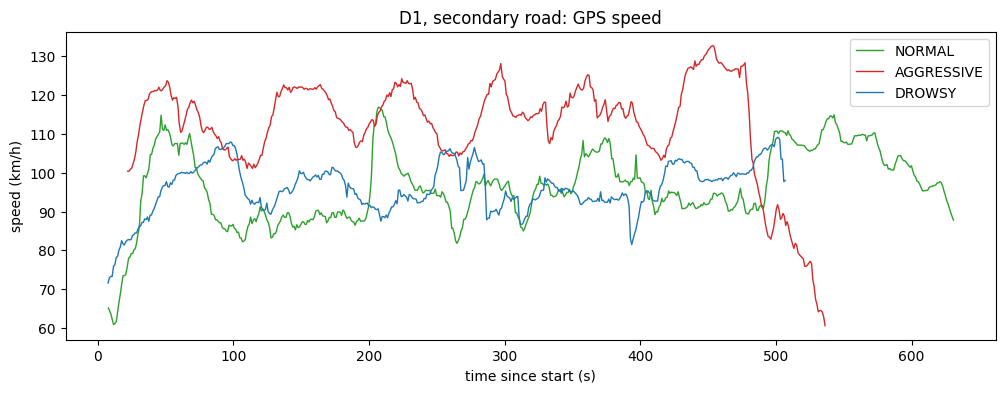

In [10]:
fig, ax = plt.subplots()
for behavior, t in d1_trips.items():
    ax.plot(t["gps"]["time"], t["gps"]["speed_kmh"], label=behavior, color=COLORS[behavior], lw=1)
ax.set_xlabel("time since start (s)")
ax.set_ylabel("speed (km/h)")
ax.set_title("D1, secondary road: GPS speed")
ax.legend()
plt.show()

### 3b. Accelerations

We use the Kalman-filtered columns. We checked them against the labelled events:
- **`acc_z_kf`** = forward/backward. Negative = **braking**, positive = **accelerating**.
- **`acc_y_kf`** = sideways (**turning**).
- `acc_x_kf` = up/down (bumps on the road).

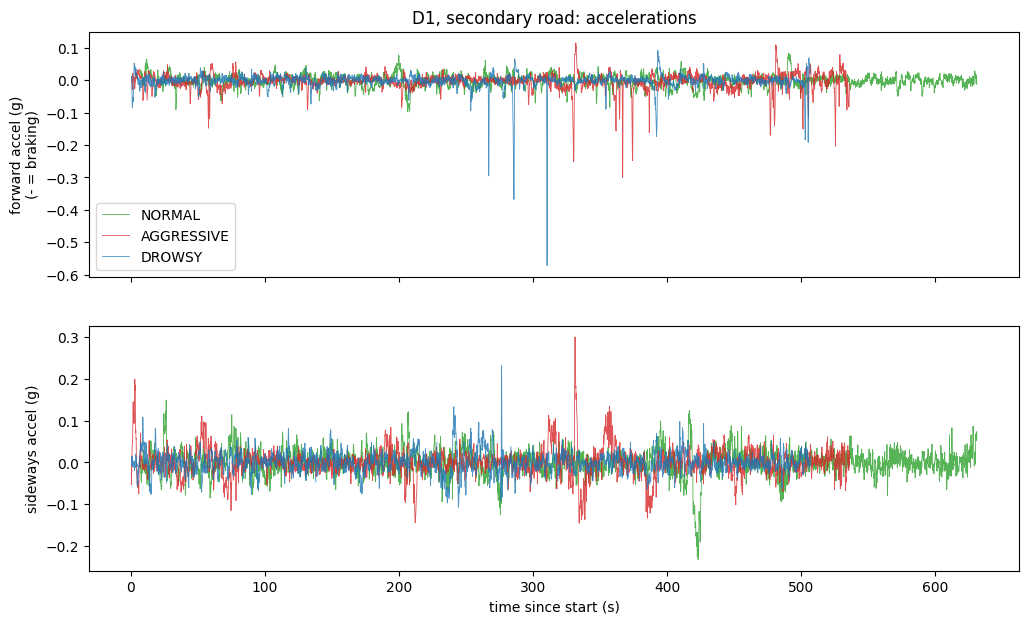

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for behavior, t in d1_trips.items():
    a = t["accel"]
    axes[0].plot(a["time"], a["acc_z_kf"], label=behavior, color=COLORS[behavior], lw=0.6, alpha=0.8)
    axes[1].plot(a["time"], a["acc_y_kf"], label=behavior, color=COLORS[behavior], lw=0.6, alpha=0.8)
axes[0].set_ylabel("forward accel (g)\n(- = braking)")
axes[1].set_ylabel("sideways accel (g)")
axes[1].set_xlabel("time since start (s)")
axes[0].set_title("D1, secondary road: accelerations")
axes[0].legend()
plt.show()

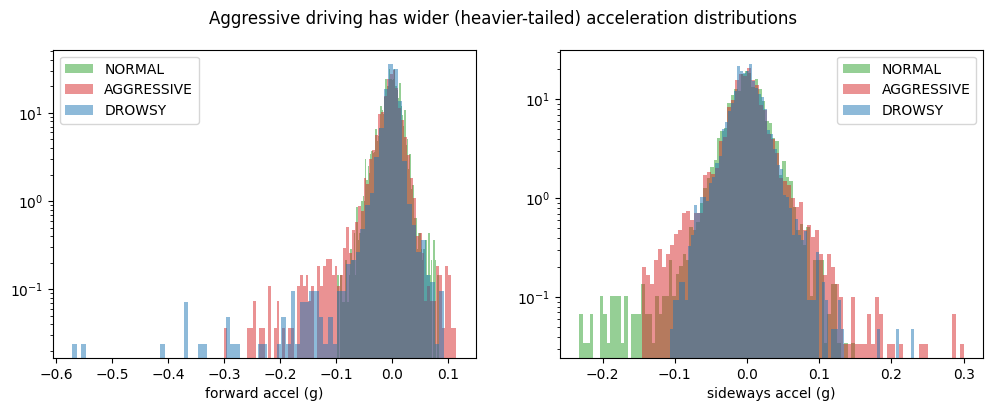

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for behavior, t in d1_trips.items():
    a = t["accel"]
    axes[0].hist(a["acc_z_kf"], bins=80, alpha=0.5, color=COLORS[behavior], label=behavior, density=True)
    axes[1].hist(a["acc_y_kf"], bins=80, alpha=0.5, color=COLORS[behavior], label=behavior, density=True)
axes[0].set_xlabel("forward accel (g)")
axes[1].set_xlabel("sideways accel (g)")
for ax in axes:
    ax.set_yscale("log")
    ax.legend()
fig.suptitle("Aggressive driving has wider (heavier-tailed) acceleration distributions")
plt.show()

### 3c. Detected events (the paper's inertial events)

In [13]:
counts = {
    behavior: t["events"].groupby(["event_name", "level_name"]).size()
    for behavior, t in d1_trips.items()
}
pd.DataFrame(counts).fillna(0).astype(int)

NORMAL  AGGRESSIVE  DROWSY
event_name level_name                            
braking    high             0           0       1
           low              0           4       3
           medium           0           5       2
turning    low              3           1       2
           medium           0           2       1

### 3d. Lane position (camera)

`lane_offset_m` is the car's distance from the lane centre. We keep only the rows where the
lane detector was working (`lane_state == 2`). Drowsy drivers should drift more.

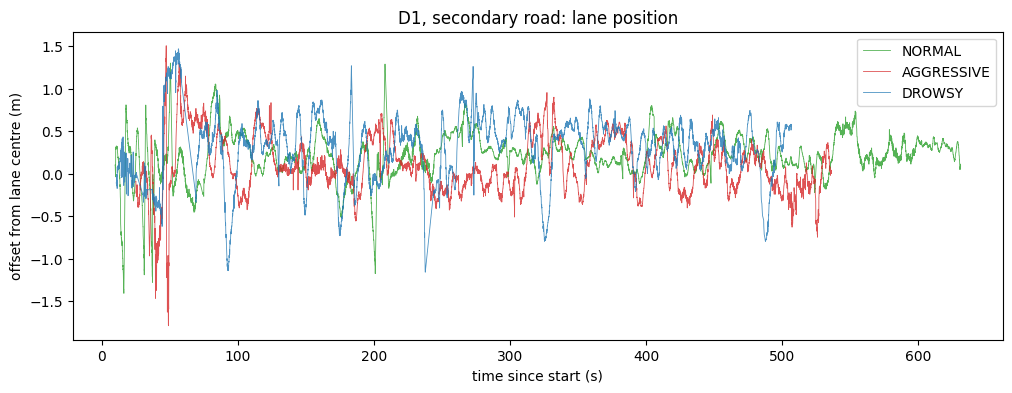

In [14]:
fig, ax = plt.subplots()
for behavior, t in d1_trips.items():
    l = t["lanes"]
    l = l[l["lane_state"] == 2]
    ax.plot(l["time"], l["lane_offset_m"], label=behavior, color=COLORS[behavior], lw=0.6, alpha=0.8)
ax.set_xlabel("time since start (s)")
ax.set_ylabel("offset from lane centre (m)")
ax.set_title("D1, secondary road: lane position")
ax.legend()
plt.show()

### 3e. Distance to the car ahead (camera)

`-1` means no car was detected, so we drop those rows.

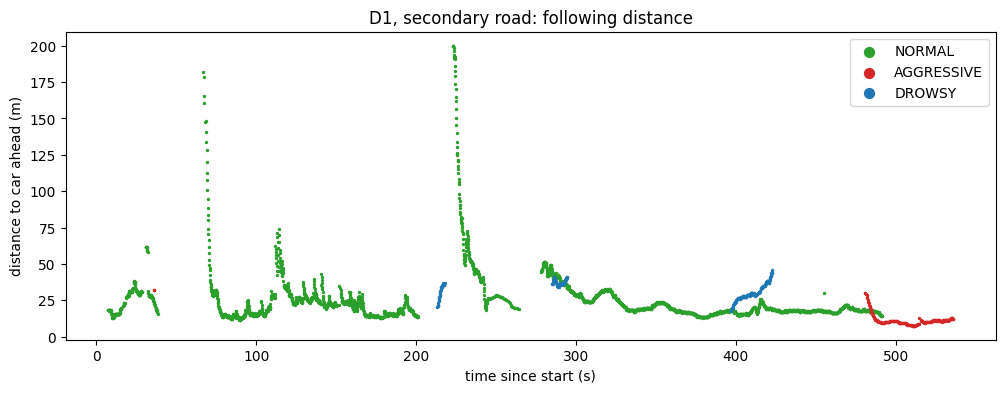

In [15]:
fig, ax = plt.subplots()
for behavior, t in d1_trips.items():
    v = t["vehicles"]
    v = v[v["dist_ahead_m"] > 0]
    ax.scatter(v["time"], v["dist_ahead_m"], s=2, label=behavior, color=COLORS[behavior])
ax.set_xlabel("time since start (s)")
ax.set_ylabel("distance to car ahead (m)")
ax.set_title("D1, secondary road: following distance")
ax.legend(markerscale=5)
plt.show()

## 4. The app's own trip scores (`SEMANTIC_FINAL.txt`)

For each trip the DriveSafe app saved 7 scores out of 100 (accelerations, brakings, turnings,
lane weaving, lane drifting, overspeeding, car-following) and 3 ratios (normal, drowsy, aggressive).
These are the paper's results. In later steps we will compute our own version and compare.

In [16]:
summary = load_summaries(trips)
score_cols = ["score_accel", "score_braking", "score_turning", "score_weaving",
              "score_drifting", "score_overspeed", "score_carfollow", "score_total"]
ratio_cols = ["ratio_normal", "ratio_drowsy", "ratio_aggressive"]
summary[["driver", "behavior", "road"] + ratio_cols + ["score_total"]].head(10)

,driver,behavior,road,ratio_normal,ratio_drowsy,ratio_aggressive,score_total
0,D1,NORMAL,SECONDARY,0.644,0.147,0.209,88.8
1,D1,NORMAL,SECONDARY,0.644,0.201,0.156,87.8
2,D1,NORMAL,MOTORWAY,0.681,0.136,0.183,93.0
3,D1,AGGRESSIVE,MOTORWAY,0.509,0.089,0.403,84.2
4,D1,DROWSY,MOTORWAY,0.324,0.557,0.119,67.3
5,D1,AGGRESSIVE,SECONDARY,0.050,0.245,0.705,62.9
6,D1,DROWSY,SECONDARY,0.329,0.434,0.237,68.0
7,D2,NORMAL,MOTORWAY,0.678,0.147,0.175,90.9
8,D2,AGGRESSIVE,MOTORWAY,0.116,0.275,0.609,61.3
9,D2,DROWSY,MOTORWAY,0.425,0.414,0.160,73.2


In [17]:
summary.groupby("behavior")[score_cols].mean().round(1)

,score_accel,score_braking,score_turning,score_weaving,score_drifting,score_overspeed,score_carfollow,score_total
behavior,,,,,,,,
AGGRESSIVE,80.2,42.0,67.7,98.4,70.5,52.8,40.5,63.3
DROWSY,95.9,69.3,67.6,33.6,39.8,90.4,98.1,70.7
NORMAL,98.7,99.0,85.4,97.3,76.8,92.5,97.1,92.4


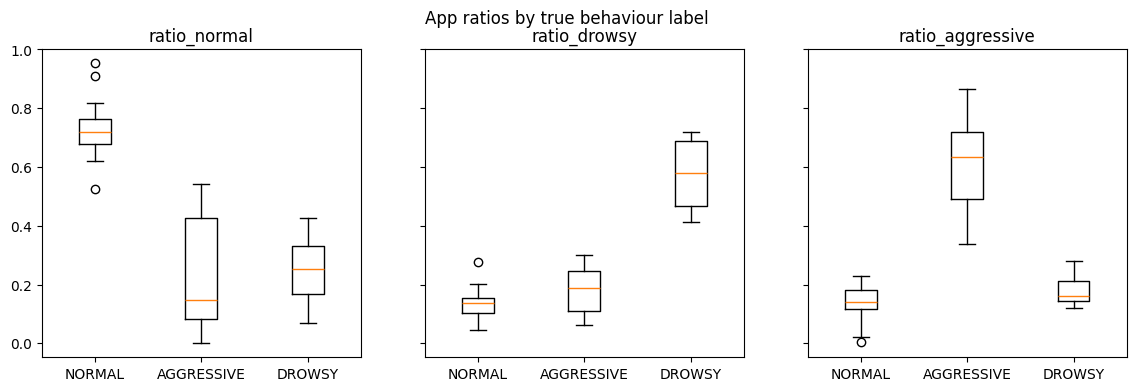

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
order = ["NORMAL", "AGGRESSIVE", "DROWSY"]
for ax, col in zip(axes, ratio_cols):
    data = [summary.loc[summary.behavior == b, col] for b in order]
    ax.boxplot(data, tick_labels=order)
    ax.set_title(col)
fig.suptitle("App ratios by true behaviour label")
plt.show()

### How well do the app's ratios predict the true label?

A simple check: for each trip, pick the behaviour with the highest ratio, then compare it with
the label in the folder name. This is the baseline we want to match or beat later.

In [19]:
pred = summary[ratio_cols].idxmax(axis=1).str.replace("ratio_", "").str.upper()
accuracy = (pred == summary["behavior"]).mean()
print(f"Baseline accuracy of the app's ratios: {accuracy:.0%} ({(pred == summary['behavior']).sum()}/{len(summary)} trips)")
pd.crosstab(summary["behavior"], pred, rownames=["true"], colnames=["predicted"])

Baseline accuracy of the app's ratios: 90% (36/40 trips)


predicted,AGGRESSIVE,DROWSY,NORMAL
true,,,
AGGRESSIVE,8,0,3
DROWSY,0,11,1
NORMAL,0,0,17


## 5. Event rates across all trips

Counting events **per 10 km** keeps long and short trips comparable.
This is the kind of feature we will use for our classifier and the safety score.

In [20]:
summary["harsh_events_per_10km"] = (
    summary[["accel_events", "braking_events", "turning_events"]].sum(axis=1) / summary["distance_km"] * 10
)
summary.groupby(["behavior", "road"])["harsh_events_per_10km"].mean().unstack().round(2)

road,MOTORWAY,SECONDARY
behavior,,
AGGRESSIVE,0.92,1.21
DROWSY,0.43,0.85
NORMAL,0.22,0.17


## Summary

- 40 trips from 6 drivers: 17 normal, 11 aggressive, 12 drowsy.
- The loader (`uah_driveset.py`) reads every file into a named table.
- The accelerometer axes in the filtered columns are: Z = forward (braking is negative), Y = sideways, X = up/down.
- Aggressive trips show wider accelerations and more harsh events. Drowsy trips show more lane drifting.
- The app's own ratios give a baseline accuracy for classifying behaviour.

**Next step (Step 2):** detect braking, acceleration and turning events ourselves from the
raw accelerometer data, and compare our events with `EVENTS_INERTIAL.txt`.